In [103]:
# Imports
import math
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
from torch.utils.data import TensorDataset, DataLoader
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

In [104]:
# Configurações para os gráficos
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (15, 6)

In [105]:
# Bloco para seleção de dispositivo (CUDA, MPS ou CPU)

if torch.cuda.is_available():
    # Prioridade 1: GPU NVIDIA (CUDA)
    device = torch.device("cuda")
    print("Dispositivo selecionado: GPU NVIDIA (CUDA)")

elif torch.backends.mps.is_available():
    # Prioridade 2: GPU Apple (MPS)
    device = torch.device("mps")
    print("Dispositivo selecionado: GPU Apple (MPS)")

else:
    # Fallback: CPU
    device = torch.device("cpu")
    print("Dispositivo selecionado: CPU")

print(f'Usando dispositivo: {device}')

Dispositivo selecionado: CPU
Usando dispositivo: cpu


### Preparando os dados

In [106]:
# Função para gerar uma série temporal sintética com componentes senidais e ruído
"""
n_pontos -> funciona como uma eficiencia do modelo quanto maior mais preciso
np.arange -> cria um vetor de 0 a 999 
as funções de seno são uma padrão, oq muda é a amplitude o periodo
"""

def dsa_gera_serie_temporal(n_pontos = 1000):
    # Cria um vetor de tempo com n_pontos igualmente espaçados
    t = np.arange(n_pontos)
    
    # Gera um sinal senoidal de baixa frequencia (período de 50)
    seno1 = np.sin(2 * np.pi * t / 50)
    
    # Gera um segundo sinal senoidal de frequencia mais alta (periodo de 25) e amplitude menor
    seno2 = 0.5 * np.sin(2 * np.pi * t / 25)
    
    #Adiciona ruido aleatorio gaussiano para simular imperfeicoes de medição
    ruido = 0.1 * np.random.randn(n_pontos)
    
    #combina os dois sinais senoidais e o ruido para formar a serie final
    serie = seno1 + seno2 + ruido
    
    #retorna a serie convertida para o tipo float32 para otimizar o uso de memoria
    return serie.astype(np.float32)

In [107]:
serie = dsa_gera_serie_temporal()

In [108]:
serie[0:5]

array([0.0756382 , 0.31059897, 0.48832053, 0.67877585, 0.94168293],
      dtype=float32)

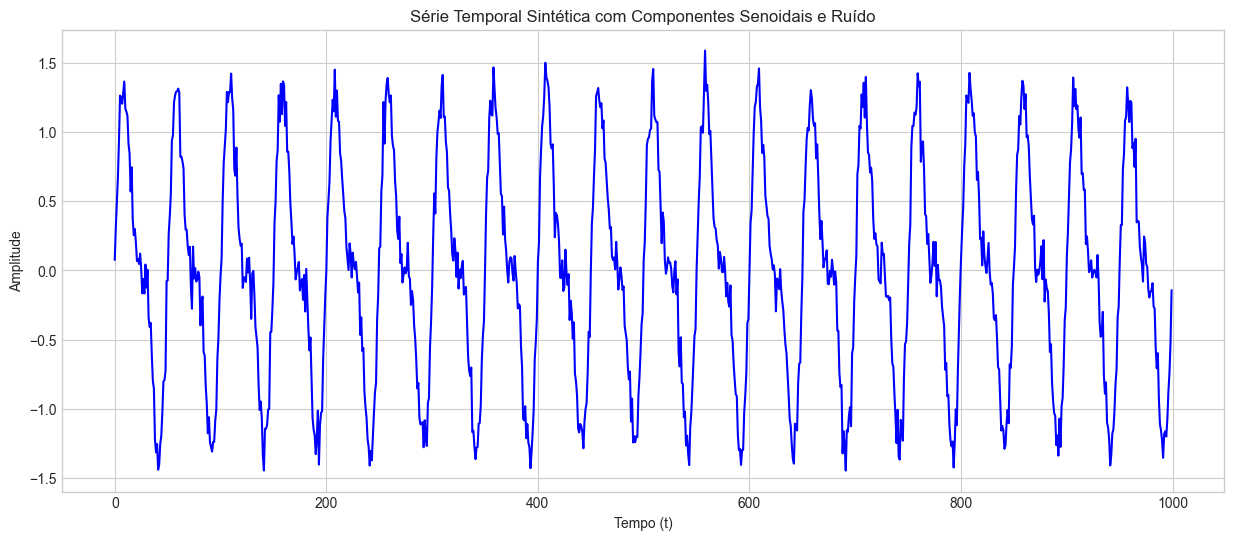

In [109]:
# Cria o eixo de tempo (mesmo tamanho da série)
t = np.arange(len(serie))

# Plot da série
plt.figure(figsize = (15, 6))
plt.plot(t, serie, color = 'blue', linewidth = 1.5)
plt.title("Série Temporal Sintética com Componentes Senoidais e Ruído")
plt.xlabel("Tempo (t)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()

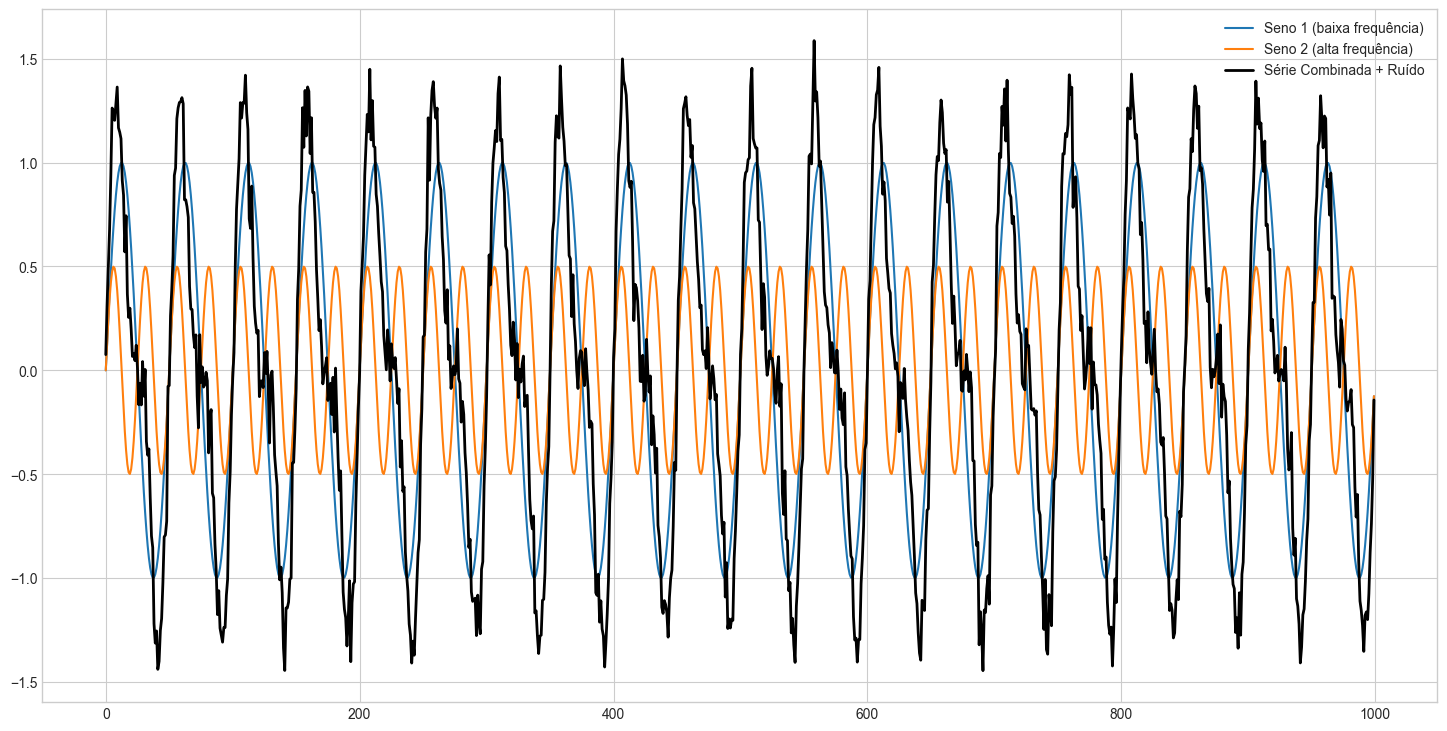

In [110]:
# Plot
plt.figure(figsize = (18, 9))
plt.plot(t, np.sin(2*np.pi*t/50), label = 'Seno 1 (baixa frequência)')
plt.plot(t, 0.5*np.sin(2*np.pi*t/25), label = 'Seno 2 (alta frequência)')
plt.plot(t, serie, label = 'Série Combinada + Ruído', color = 'black', linewidth = 2)
plt.legend(loc='upper right')  
plt.show()

### Divisão em treino e Teste

In [111]:
# Tamanho da janela
input_window = 50

In [112]:
# Fazendo cutoff
cutoff = int(len(serie) * 0.8)

In [113]:
#Fazendo repartição dos dados de treino e teste (não podemos perder a sequência)
serie_train = serie[:cutoff]
serie_test = serie[cutoff:]


### Normalizando os dados

In [114]:
#Criando o padronizador
scaler = MinMaxScaler(feature_range= (-1,1))

In [ ]:
"""
Aqui a variavel "scaler" aprende como fazer o reshape, utilizando os dados de treino. 
Para que em seguida, seja utilizado o "transform" para transformar os dados com base no que foi aprendido.
"""
scaler.fit(serie_train.reshape(-1,1))

,feature_range,"(-1, ...)"
,copy,True
,clip,False


In [116]:
#Aplicando o padronizador aos dados de treino
serie_train_scaled = scaler.transform(serie_train.reshape(-1, 1)).astype(np.float32)

In [117]:
#Aplicando o padronizador aos dados de teste
serie_test_scaled = scaler.transform(serie_test.reshape(-1, 1)).astype(np.float32)

### Criando a sequência de entrada e saída

In [118]:
def dsa_cria_sequencias(dados, input_window):
    
    #Inicializa uma lista vazia para armazenar as sequencias geradas
    sequencias = []
    
    #Calcula o comprimento total dos dados
    L = len(dados)
    
    #percorre os dados criando janelas deslizantes de tamanho input_winodw
    for i in range(L - input_window):
        #Seleciona um trecho dos dados como sequencia de entrada
        seq = dados[i:i + input_window]
        
        #seleciona o valor seguinte como rítulo (saída esperada)
        label = dados[i + input_window:i + input_window + 1]
        
        #armazena a tupla (sequência de entrada, rótulo) na lista
        sequencias.append((seq, label))
    return sequencias

In [119]:
#aplicando a função 

train_sequences = dsa_cria_sequencias(serie_train_scaled, input_window)
teste_sequences = dsa_cria_sequencias(serie_test_scaled, input_window)

In [120]:
# função para converter os dados para o formato de sensor
def dsa_converte_para_tensor(data):
    X = torch.tensor([item[0] for item in data], dtype = torch.float32)
    y = torch.tensor([item[1] for item in data], dtype = torch.float32)
    return X, y

In [121]:
X_train, y_train = dsa_converte_para_tensor(train_sequences)
X_test, y_test = dsa_converte_para_tensor(teste_sequences)

### Criação dos DataLoaders

DataLoaders no PyTorch são objetos que organizam o fluxo de dados durante o treinamento. Eles recebem um dataset e produzem lotes iteráveis e prontos para serem enviados ao modelo. Eles também cuidam de paralelizar a leitura, aplicar transformações e controlar o tamanho dos batches, facilitando o treinamento eficiente.

In [122]:
# Tamanho de cada batch
# Isso é um hiperparâmetro
batch_size = 32


In [123]:
# ria os objetos do tipo TensorDataset
train_dataset = TensorDataset(X_train, y_train)
test_dataset = TensorDataset(X_test, y_test)

In [124]:
# Criando os dataloaders
# shuffle = embaralhar
train_loader = DataLoader(train_dataset, batch_size = batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size= batch_size, shuffle=False)

In [125]:
# Classe responsável por adicionar codificação posicional aos embedings de entrada em um Transformer

"""
nn.Module -> está herdando o modulo nn do pyTorch
"""

class PositionalEnconding(nn.Module):
    
    #Método constutor da class
    def __init__(self, d_model, dropout = 0.1, max_len = 5000):
        
        #Inicializa a classe base nn.Module
        super(PositionalEnconding, self).__init__()
        
        #Define uma camada de dropout para regularização (evitar overfitting)
        self.dropout = nn.Dropout(p = dropout)
        
        #Cria uma matriz de zeros para armazenar as codificações posicionais
        pe = torch.zeros(max_len, d_model)
        
        #Cria um vetor com as posições de 0 até max_len
        position = torch.arange(0, max_len, dtype= torch.float).unsqueeze(1)
        
        #Calcula o termo divisor baseado na frequência de cada dimensão
        #Eesse termo controla a variação senoidal(seno) conforme o índice da dimensão
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        
        #aplica a função seno nas dimensões pares
        
        pe[:, 0::2] = torch.sin(position * div_term)
        
        #aplica a função cosseno nas dimensões ímpares
        pe[:, 1::2] = torch.cos(position * div_term)
        
        #Adiciona uma dimensão extra no ínicio para representar o batch (lote)
        pe = pe.unsqueeze(0)
        
        self.register_buffer('pe', pe)
        
    def forward(self, x):
        
        #Soma a codificação posicional ao embedding de entrada
        
        x = x + self.pe[:, :x.size(1), :]
        
        #aplica o droput e retorna o resultado
        return self.dropout(x)
        

In [126]:
class TimeSeriesTransformer(nn.Module):
    
    #Método construtor do moedelo, com hipermarametro ajustáveis
    def __init__(self, input_dim = 1, d_model = 32, nhead = 2, num_layers = 2, dropout = 0.1):
        
        #inicializa a classe base nn.module
        super(TimeSeriesTransformer, self).__init__()
        
        #define o tipo de modelo (apenas para identificação)
        self.model_type = 'Transformer'
        
        #armazena o tamanho da dimensão do embedding (vetor interno do modelo)
        self.d_model = d_model
        
        #camada linear para transformar a entrada no espaço de dimensão d_model
        self.encoder = nn.Linear(input_dim, d_model)
        
        #modulo de codificação posicional para adicionar informação de ordem temporal
        self.pos_encoder = PositionalEnconding(d_model, dropout)
        
        #Define uma camada de codificação Transformer padrão PyTorch
        
        encoder_layers = nn.TransformerEncoderLayer(
            d_model = d_model,       # dimensão do mebeding
            nhead = nhead,        # numero de cabeças de atenção
            dropout = dropout,       # taxa de dropout para regularização
            batch_first = True      # garante que o batch seja a primeira dimensão (B, T ,D)
        )
        
        #Cria o empilhamernto de múltiplas camadas de codificação Transformer
        self.transformer_encoder = nn.TransformerEncoder(encoder_layers, num_layers = num_layers)
        
        # Camada linear final para mapear de volta à dimensão original da entrada
        self.decoder = nn.Linear(d_model, input_dim)
    
    #Método que define o fluxo de dados (foward pass)
    
    def forward(self, src):
        
        #Projeta os dados de entrada para o espaço de embedding e escala pela raiz de d_model
        src = self.encoder(src) * math.sqrt(self.d_model)
        
        # Adiciona as codificações posicionais para preservar a ordem temporal
        src = self.pos_encoder(src)
        
        #Passa as sequências codificadas pelo bloco Transfoermer
        output = self.transformer_encoder(src)
        
        # Utiliza a média de todas as saídas da sequência para gerar a previsão final
        #(isso é mais estável do que usar apenas o último token)
        output = output.mean(dim = 1)
        
        # passa o resultado pela camda decodificadora para retornar a dimensão original
        output = self.decoder(output)
        
        #retorna a previsão final da série temporal
        return output
        

In [127]:
# Cria o objeto (instância da classe) e manda para o device
modelo_dsa = TimeSeriesTransformer().to(device)

In [128]:
print(modelo_dsa)

TimeSeriesTransformer(
  (encoder): Linear(in_features=1, out_features=32, bias=True)
  (pos_encoder): PositionalEnconding(
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (transformer_encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=32, out_features=32, bias=True)
        )
        (linear1): Linear(in_features=32, out_features=2048, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=2048, out_features=32, bias=True)
        (norm1): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (decoder): Linear(in_features=32, out_features=1, bias=True)
)


### Criando a função de erro

In [129]:
# Define a função de erro 
criterion = nn.MSELoss()

In [130]:
# Cria o otimizador
optmizer = torch.optim.Adam(modelo_dsa.parameters(), lr = 0.0005)

### Treinamento do modelo 

In [135]:
#numero de epocas de treino
epochs = 50

In [136]:
# coloca o modelo em modo de treino
modelo_dsa.train()

TimeSeriesTransformer(
  (encoder): Linear(in_features=1, out_features=32, bias=True)
  (pos_encoder): PositionalEnconding(
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (transformer_encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=32, out_features=32, bias=True)
        )
        (linear1): Linear(in_features=32, out_features=2048, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=2048, out_features=32, bias=True)
        (norm1): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (decoder): Linear(in_features=32, out_features=1, bias=True)
)

In [142]:
%%time

#loop principal de treinamento, que se repete pelo num total de épocas definido

for epoch in range(epochs):
    
    #inicializa a variavel quie acumula a perda total por epoca
    total_loss = 0 
    
    #cria uma barra de progresso para monitorar o andamento do treinamento
    pbar = tqdm(train_loader, desc = f'Epoch {epoch + 1} / {epochs}')
    
    #itera sobre cada lote (batch) de dados de treino
    for seq, label in pbar:
        seq, label = seq.to(device), label.to(device)
        
        #zera os gradientes acumulados das iterações anteriores
        optmizer.zero_grad()
        
        #passa o lote de entrada pelo modelo para obter as previsões
        y_pred = modelo_dsa(seq)
        
        #calcula o erro (loss) entre a previsão do modelo e o valor real
        loss = criterion(y_pred, label.squeeze(-1))
        
        # propaga o erro de volta pela rede (backpropagation) para calcular os gradientes
        loss.backward()
        
        #atualiza os pesos do modelo com base nos gradientes calculados
        optmizer.step()
        
        #soma o valor numerico da perta atual a perda total da epoca
        total_loss += loss.item()
        
        #atualiza a barra de progresso mostrando a perda do lote atual
        pbar.set_postfix({'loss' : loss.item()})
        
    #calcula a perda media ao final da epoca
    avg_loss = total_loss / len(train_loader)
            
    #exibe no console a perda média da epoca concluída
    print(f'Epoch {epoch + 1} concluida, Loss média: {avg_loss:.6f}')
        
   
        
        

Epoch 1 / 50: 100%|██████████| 24/24 [00:03<00:00,  7.82it/s, loss=0.207]


Epoch 1 concluida, Loss média: 0.271551


Epoch 2 / 50: 100%|██████████| 24/24 [00:03<00:00,  7.95it/s, loss=0.213]


Epoch 2 concluida, Loss média: 0.267725


Epoch 3 / 50: 100%|██████████| 24/24 [00:03<00:00,  7.63it/s, loss=0.258]


...

Epoch 48 concluida, Loss média: 0.011705


Epoch 49 / 50: 100%|██████████| 24/24 [00:03<00:00,  6.57it/s, loss=0.009]  


Epoch 49 concluida, Loss média: 0.010628


Epoch 50 / 50: 100%|██████████| 24/24 [00:03<00:00,  6.69it/s, loss=0.0116] 

Epoch 50 concluida, Loss média: 0.010448
CPU times: total: 12min 39s
Wall time: 2min 35s


## Avaliando o modelo

In [143]:
#coloca o modelo em modo de avaliação 
modelo_dsa.eval()

TimeSeriesTransformer(
  (encoder): Linear(in_features=1, out_features=32, bias=True)
  (pos_encoder): PositionalEnconding(
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (transformer_encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=32, out_features=32, bias=True)
        )
        (linear1): Linear(in_features=32, out_features=2048, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=2048, out_features=32, bias=True)
        (norm1): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (decoder): Linear(in_features=32, out_features=1, bias=True)
)

In [144]:
#preparando listas para armazenar os resultados
all_predctions = []
all_actuais = []

In [145]:
#desativa o calcuolo de gradientes para economizar memoria e acelear a inferência

with torch.no_grad():
    
    #itera sobre os lotes (batches) do conjusto de teste
    
    for seq, label in test_loader:
        
        #move os dados e rotulos para o dispositivo
        seq, label = seq.to(device), label.to(device)
        
        #gera as previsoes do modelo para o lote atual
        y_pred = modelo_dsa(seq)
        
        #converte as previsoes para numpy e adicionando as listas de previsoes
        all_predctions.extend(y_pred.cpu().numpy())
        
        #converte os valores reais (rotulos)  para numpy e adicionando as listas de valores reais
        all_actuais.extend(label.cpu().numpy())
    

In [146]:
#desnormalizando os dados
actual_predctions = scaler.inverse_transform(np.array(all_predctions))
y_test_original = scaler.inverse_transform(np.array(all_actuais).reshape(-1, 1))

In [147]:
#calculando as metricas
mse = mean_squared_error(y_test_original, actual_predctions)
rmse = mse ** 0.5
mae = mean_absolute_error(y_test_original, actual_predctions)

In [148]:
print("MSE:", mse)
print("RMSE:", rmse)
print("MAE:", mae)

MSE: 0.06841271370649338
RMSE: 0.2615582415189653
MAE: 0.22170761227607727


In [ ]:
# Cria a figura
plt.figure(figsize = (20, 8))

# Série original completa (sem normalização)
plt.plot(np.arange(len(serie)), serie, label = 'Dados Originais', color = 'gray', alpha = 0.6)

# Eixo de tempo do conjunto de teste
test_start = len(serie_train) # ponto onde começa o teste
test_time_axis = np.arange(test_start + input_window, len(serie))

# Plotar os valores reais e as previsões
plt.plot(test_time_axis, y_test_original, label = 'Valores Reais (Teste)', color = 'blue', linewidth = 2)
plt.plot(test_time_axis, actual_predictions, label = 'Previsões (Transformer)', color = 'red', linestyle = '--', linewidth = 2)

plt.title("Previsão de Série Temporal com Transformer (Sem Vazamento de Dados)")
plt.xlabel("Tempo")
plt.ylabel("Valor")
plt.legend()
plt.grid(True)

# Zoom na região de teste
plt.xlim(test_start - 100, len(serie))
plt.show()

## Deploy do modelo

In [ ]:
# função apra forecast

def dsa_previsao_futuro(model, start_sequence, future_steps):
    
    """
    prevê múltiplos passos no futuro de forma autorregressiva
    """
    
    model.eval()
    
    #lista para guardar as previsões futuras
    future_predctions = []
    
    #a sequencia atual começa com os dados de entrada
    current_sequence = start_sequence.clone().detach()
    
    #desativando gradientes
    
    with torch.no_grad():
        
        #loop pelos passos futuros no tempo 
        for i in range(future_steps):
            
            #preve o próximo passo 
            next_pred = modelo_dsa(current_sequence.unsqueeze(0)) #adiciona dimensão de lote
            
            #guardar a previsão
            future_predctions.append(next_pred.item())
            
            #atualiza a sequencia: remove o primeiro ponto e adiciona a previsão no final
            # o shape de next_pred é [1, 1], precisamos ajusta-lo para [1,1,1] para concatenar
            next_pred_trensor = torch.tensor([[next_pred.item()]], device = device)
            current_sequence = torch.cat(current_sequence[1:], next_pred_trensor, dim = 0)
    return np.array(future_predctions)

In [ ]:
# --- Usando a função para prever o futuro ---

# 1. Pegar a última sequência do nosso dataset como ponto de partida
last_sequence_real = X_test[-1].to(device)

# 2. Definir quantos passos no futuro queremos prever
steps_to_forecast = 200

# 3. Gerar o forecast
future_forecast_normalized = dsa_previsao_futuro(modelo_dsa, last_sequence_real, steps_to_forecast)

# 4. Desnormalizar os resultados para a escala original
future_forecast = scaler.inverse_transform(future_forecast_normalized.reshape(-1, 1))

In [ ]:
# Imprimindo as primeiras linhas do vetor com as previsões
future_forecast[0:5]

In [ ]:
# Cria a figura para o plot
plt.figure(figsize = (20, 12))

# Série temporal original completa
plt.plot(np.arange(len(serie)), serie, label = 'Dados Históricos Reais (Treino)', color = 'gray', alpha = 0.7)

# Eixo de tempo do conjunto de teste (baseado na divisão original)
test_start = len(serie_train)
test_time_axis = np.arange(test_start + input_window, len(serie))

# Previsões no conjunto de teste
plt.plot(test_time_axis, y_test_original, label = 'Dados Históricos Reais (Teste)', color = 'blue')
plt.plot(test_time_axis, actual_predictions, label = 'Previsões no Teste', color = 'red', linestyle = '--')

# Forecast 
future_time_axis = np.arange(len(serie), len(serie) + steps_to_forecast)
plt.plot(future_time_axis, future_forecast, label = 'Forecast Futuro', color = 'green', linewidth = 3)

# Linha vertical indicando o início do forecast
plt.axvline(x = len(serie)-1, color = 'black', linestyle = '--', label = 'Início do Forecast')

plt.title("Forecast de Série Temporal com Transformer")
plt.xlabel("Tempo")
plt.ylabel("Valor")
plt.legend()
plt.grid(True)
plt.show()